**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**10 | Raw-IMU Temporal Classification with PyTorch**

![Stage 10 scientific workflow](../../images/10_workflow.svg)

**Objective:** Train a compact 1D-CNN on six-channel HARTH acceleration windows and evaluate its bounded, participant-disjoint Development performance.

**Dataset:** The pinned HARTH v2.0 Development cohort, with up to 500 label-pure, two-second windows sampled per participant.

**Notebook Scope:** Fit channel scaling on Train only, train the temporal CNN for five epochs and inspect Validation Macro F1 and class-specific errors. Reserved Test recordings S023 and S032 are not loaded. Sampling and evaluation differ from the full-cohort classical ML comparison, so direct model rankings across these protocols are not justified.

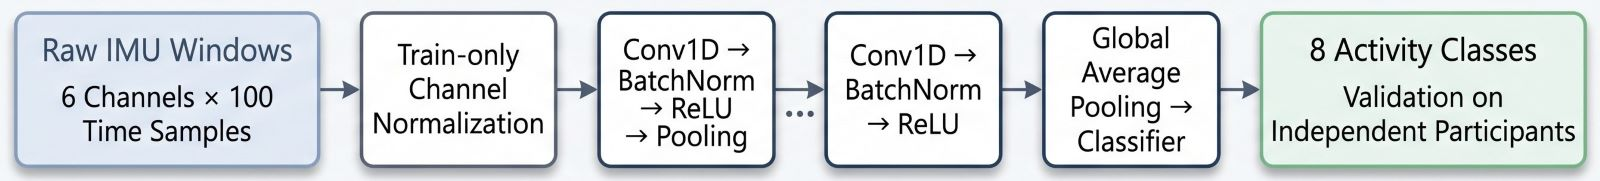

**01. Imports and Research Environment**

In [1]:
# =================== 01. Imports and Research Environment ====================

# ----------- 1. Import standard-library tools for portable paths. ------------
import sys
from pathlib import Path

# --------------- 2. Import NumPy and pandas for source arrays. ---------------
import numpy as np
import pandas as pd

# --------------- 3. Import plotting for saved learning curves. ---------------
import matplotlib.pyplot as plt

# --------------- 4. Import PyTorch for the temporal CNN model. ---------------
import torch

# -------------- 5. Import the notebook table display function. ---------------
from IPython.display import display

# ---------- 6. Discover the project root without local drive paths. ----------
root = Path.cwd().resolve()
while not (root / "python_modules/core/data_loading.py").is_file():
    if root.parent == root:
        raise RuntimeError("Run inside the human-movement-intelligence repository")
    root = root.parent

# ---------- 7. Register the two reusable research code directories. ----------
sys.path.insert(0, str(root / "python_modules"))
sys.path.insert(0, str(root / "wearable_activity_recognition/code/src"))

# ----------- 8. Import original HARTH and PyTorch model utilities. -----------
from harth_data import HARTH_SUBJECTS, ACTIVITY_NAMES, prepare_harth_window_cohort
from core.data_splitting import split_group_indices
from core.temporal_cnn import TemporalCNN, train_temporal_cnn

# ---------- 9. Report the actual PyTorch and execution environment. ----------
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Python environment:", sys.executable)

PyTorch: 2.12.1+cpu
CUDA available: False
Python environment: c:\Users\Reza\AppData\Local\Programs\Python\Python314\python.exe


**02. Define the Bounded Raw-Signal Experiment**

Use all 29 Development participants with a deterministic cap of 500 eligible windows per person, sampled without using labels. The saved cohort contains 14,201 windows; this computational cap can change activity representation and does not balance the classes.

In [2]:
# ================== 02. Construct Bounded Raw-Window Cohort ==================

# ----------- 1. Define the originally reserved Test participants. ------------
RESERVED_TEST = {"S023", "S032"}

# -------------- 2. Select only the 29 Development participants. --------------
DEVELOPMENT_SUBJECTS = sorted(set(HARTH_SUBJECTS) - RESERVED_TEST)

# ------------- 3. Preserve the eight documented activity labels. -------------
TASK_CLASSES = tuple(range(1, 9))

# ------------ 4. Cap each subject at 500 eligible source windows. ------------
MAX_WINDOWS_PER_SUBJECT = 500

# ------------ 5. Verify cohort size and reserved Test exclusion. -------------
assert len(DEVELOPMENT_SUBJECTS) == 29
assert not (set(DEVELOPMENT_SUBJECTS) & RESERVED_TEST)

# ----------- 6. Build six-axis, label-pure, capped signal windows. -----------
X, y, metadata, overview = prepare_harth_window_cohort(
    subjects=DEVELOPMENT_SUBJECTS,
    data_dir=root / "data/raw/harth_v2",
    task_classes=TASK_CLASSES,
    max_windows_per_subject=MAX_WINDOWS_PER_SUBJECT,
    window_size=100, step_size=50, sampling_rate=50,
)

# --------- 7. Display actual per-person sampling and class coverage. ---------
display(overview)

# ----------- 8. Report raw tensor dimensions, labels and subjects. -----------
print("Real raw IMU tensor:", X.shape)
print("Label vector:", y.shape)
print("Subjects:", metadata["subject_id"].nunique())

Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S006.csv
HARTH subject S006: 408,709 rows, 6 sensors
Input signal: 408,709 samples, 6 channels
Candidate windows: 8,173
Retained windows: 7,441 | Shape: (7441, 6, 100)
Rejected candidates: 732
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S008.csv
HARTH subject S008: 418,989 rows, 6 sensors
Input signal: 418,989 samples, 6 channels
Candidate windows: 8,378
Retained windows: 7,564 | Shape: (7564, 6, 100)
Rejected candidates: 814
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S009.csv
HARTH subject S009: 154,464 rows, 6 sensors
Input signal: 154,464 samples, 6 channels
Candidate windows: 3,088
Retained windows: 2,885 | Shape: (2885, 6, 100)
Rejected candidates: 203
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S010.csv
HARTH subject S010: 351,649 rows, 6 sensors
Input signal: 351,649 samples, 6 channels
Candidate windows: 7,031
Retai

D:\human-movement-intelligence\studies\wearable_activity_recognition\src\harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10, 11, 17] (4,512 rows in S030.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S030: 245,994 rows, 6 sensors
Input signal: 245,994 samples, 6 channels
Candidate windows: 4,918
Retained windows: 3,335 | Shape: (3335, 6, 100)
Rejected candidates: 1,583
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S031.csv


D:\human-movement-intelligence\studies\wearable_activity_recognition\src\harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10, 11] (334 rows in S031.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S031: 269,560 rows, 6 sensors
Input signal: 269,560 samples, 6 channels
Candidate windows: 5,390
Retained windows: 4,411 | Shape: (4411, 6, 100)
Rejected candidates: 979
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S033.csv
HARTH subject S033: 201,688 rows, 6 sensors
Input signal: 201,688 samples, 6 channels
Candidate windows: 4,032
Retained windows: 3,687 | Shape: (3687, 6, 100)
Rejected candidates: 345
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S035.csv
HARTH subject S035: 181,251 rows, 6 sensors
Input signal: 181,251 samples, 6 channels
Candidate windows: 3,624
Retained windows: 3,337 | Shape: (3337, 6, 100)
Rejected candidates: 287
Using cached HA

D:\human-movement-intelligence\studies\wearable_activity_recognition\src\harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10] (1,422 rows in S037.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S037: 206,379 rows, 6 sensors
Input signal: 206,379 samples, 6 channels
Candidate windows: 4,126
Retained windows: 3,468 | Shape: (3468, 6, 100)
Rejected candidates: 658
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S038.csv
HARTH subject S038: 184,992 rows, 6 sensors
Input signal: 184,992 samples, 6 channels
Candidate windows: 3,698
Retained windows: 3,355 | Shape: (3355, 6, 100)
Rejected candidates: 343
Temporal cohort: 29 subjects, X=(14201, 6, 100)


,subject_id,raw_samples,candidate_retained_windows,eligible_windows,sampled_windows,excluded_out_of_task_windows,observed_sampled_classes
0,S006,408709,7441,6708,500,733,7
1,S008,418989,7564,7392,500,172,5
2,S009,154464,2885,201,201,2684,4
3,S010,351649,6077,6077,500,0,6
4,S012,382414,7309,7309,500,0,8
5,S013,369077,6451,6402,500,49,8
6,S014,366487,6409,6299,500,110,8
7,S015,418392,7626,7453,500,173,8
8,S016,355418,6484,6272,500,212,7
9,S017,366609,6841,6678,500,163,8


Real raw IMU tensor: (14201, 6, 100)
Label vector: (14201,)
Subjects: 29


**03. Create Subject-Disjoint Train and Validation Groups**

Split whole participants rather than overlapping windows. The `unused_development` partition contains three Development participants and is distinct from reserved final Test identities S023 and S032.

In [3]:
# ================ 03. Separate Train and Validation Subjects =================

# ------------ 1. Split complete subjects with the fixed seed 42. -------------
parts = split_group_indices(
    metadata["subject_id"].to_numpy(),
    train_fraction=0.70, validation_fraction=0.20,
    test_fraction=0.10, random_state=42,
)

# ---------- 2. Store the actual identities in all three partitions. ----------
group_names = {
    name: sorted(metadata.iloc[idx]["subject_id"].unique().tolist())
    for name, idx in parts.items()
}

# --------- 3. Assert Train and Validation contain different people. ----------
assert not (set(group_names["train"]) & set(group_names["validation"]))
assert not (set(group_names["train"]) & set(group_names["test"]))
assert not (set(group_names["validation"]) & set(group_names["test"]))

# ------------ 4. Select only Train and Validation for this pilot. ------------
train_rows = parts["train"]
validation_rows = parts["validation"]

# -------------- 5. Extract aligned raw signals and task labels. --------------
X_train, y_train = X[train_rows], y[train_rows]
X_validation, y_validation = X[validation_rows], y[validation_rows]

# -------- 6. Display Train, Validation and unused Development counts. --------
display(pd.DataFrame([
    {"role": "Train", "subjects": len(group_names["train"]),
     "windows": len(train_rows), "subject_ids": ", ".join(group_names["train"])},
    {"role": "Validation", "subjects": len(group_names["validation"]),
     "windows": len(validation_rows), "subject_ids": ", ".join(group_names["validation"])},
    {"role": "Unused development", "subjects": len(group_names["test"]),
     "windows": len(parts["test"]), "subject_ids": ", ".join(group_names["test"])},
]))

# ----------- 7. Confirm original Test data have never been loaded. -----------
print("Original reserved final Test loaded: NO")

Independent groups: 29
train: 20 groups | 10,000 rows
validation: 6 groups | 2,701 rows
test: 3 groups | 1,500 rows


,role,subjects,windows,subject_ids
0,Train,20,10000,"S006, S010, S013, S014, S015, S017, S018, S020..."
1,Validation,6,2701,"S009, S012, S019, S022, S036, S037"
2,Unused development,3,1500,"S008, S016, S021"


Original reserved final Test loaded: NO


**04. Audit Source Classes and Temporal Model Input**

Check that Train contains all eight target classes and that the CNN input follows `(batch, channels, time)`, rather than the previously engineered 30-feature representation.

In [4]:
# ==================== 04. Audit Classes and Raw CNN Input ====================

# ----------- 1. Count real source classes in Train and Validation. -----------
counts = pd.DataFrame({
    "train": pd.Series(y_train).value_counts(),
    "validation": pd.Series(y_validation).value_counts(),
}).reindex(TASK_CLASSES, fill_value=0).fillna(0).astype(int)

# -------------- 2. Label all eight documented activity classes. --------------
counts.index = [f"{code}: {ACTIVITY_NAMES[code]}" for code in TASK_CLASSES]

# --------------- 3. Display the original class support table. ----------------
display(counts)

# ----------- 4. Require each task class in the Train participants. -----------
assert (counts["train"] > 0).all(), "Training class coverage is incomplete."

# ----------- 5. Instantiate an untrained six-channel temporal CNN. -----------
model_preview = TemporalCNN(in_channels=6, n_classes=8)

# ------------ 6. Check the four-window forward-pass output shape. ------------
example_output = model_preview(torch.from_numpy(X_train[:4]))

# -------------- 7. Distinguish eight logits from probabilities. --------------
print("Example CNN output shape:", tuple(example_output.shape))
print("Untrained classifier output is logits, not probabilities.")

,train,validation
1: Walking,2987,453
2: Running,940,78
3: Shuffling,169,15
4: Stairs ascending,156,30
5: Stairs descending,145,32
6: Standing,1502,536
7: Sitting,3240,1363
8: Lying,861,194


Example CNN output shape: (4, 8)
Untrained classifier output is logits, not probabilities.


**05. Train the Compact 1D-CNN with Train-Only Scaling**

Estimate channel means and standard deviations from Train windows only. Train the CNN for five epochs using raw signal sequences; CPU is the default device, with CUDA used when available. This is a bounded feasibility experiment, not a hyperparameter-matched benchmark against classical models.

In [5]:
# =================== 05. Train the Compact PyTorch 1D-CNN ====================

# ----------- 1. Set a bounded five-epoch research training budget. -----------
EPOCHS = 5

# ---------- 2. Fix batch size, learning rate and available device. -----------
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# ------------- 3. Report the actual CPU or optional CUDA device. -------------
print("Training device:", DEVICE)

# -------- 4. Fit scaling and model weights using Train subjects only. --------
model, history, validation_pred, scaling = train_temporal_cnn(
    X_train=X_train, y_train=y_train,
    X_validation=X_validation, y_validation=y_validation,
    classes=TASK_CLASSES,
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    learning_rate=LEARNING_RATE, seed=42, device=DEVICE,
)

# ---------- 5. Review saved loss and Validation Macro F1 by epoch. -----------
display(history.round(4))

# --------- 6. Display the Train-fitted channel normalisation means. ----------
print("Channel means fitted from Train:", np.round(scaling["channel_mean"], 4))

Training device: cpu
Epoch 1/5 | loss=0.7939 | validation Macro F1=0.5914
Epoch 2/5 | loss=0.3313 | validation Macro F1=0.5980
Epoch 3/5 | loss=0.2590 | validation Macro F1=0.6017
Epoch 4/5 | loss=0.2173 | validation Macro F1=0.6254
Epoch 5/5 | loss=0.1918 | validation Macro F1=0.6659


,epoch,train_loss,validation_macro_f1,validation_accuracy,validation_balanced_accuracy
0,1,0.7939,0.5914,0.9341,0.5989
1,2,0.3313,0.5980,0.9422,0.6044
2,3,0.2590,0.6017,0.9485,0.6082
3,4,0.2173,0.6254,0.9500,0.6222
4,5,0.1918,0.6659,0.9530,0.6459


Channel means fitted from Train: [-0.8837 -0.0212 -0.1242 -0.711  -0.0967 -0.3982]


**06. Visualise Learning Curves and Validation Scores**

Plot training loss and Validation Macro F1 in separate panels. Report the final epoch without selecting a model using reserved Test data.

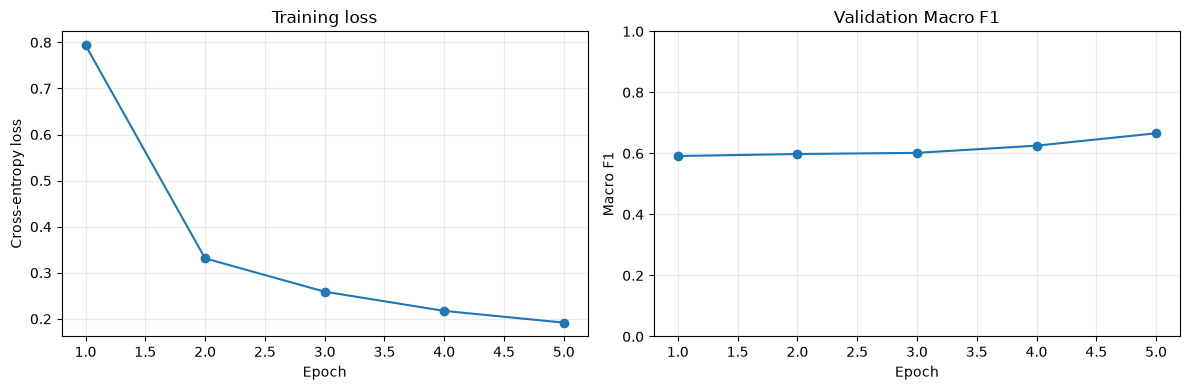

In [6]:
# =============== 06. Visualise Training and Validation Trends ================

# ---------- 1. Initialise separate training and Validation panels. -----------
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# ------------ 2. Plot the observed cross-entropy loss per epoch. -------------
axes[0].plot(history["epoch"], history["train_loss"], marker="o")
axes[0].set(title="Training loss", xlabel="Epoch", ylabel="Cross-entropy loss")
axes[0].grid(alpha=0.25)

# ------------- 3. Plot held-out-participant Validation Macro F1. -------------
axes[1].plot(history["epoch"], history["validation_macro_f1"], marker="o")
axes[1].set(title="Validation Macro F1", xlabel="Epoch",
            ylabel="Macro F1", ylim=(0, 1))
axes[1].grid(alpha=0.25)
fig.tight_layout()
plt.show()

**07. Inspect Last-Epoch Activity Classification Errors**

Examine the eight-class confusion matrix and class-specific scores for the bounded Development Validation participants.

,precision,recall,f1-score,support
Walking,0.885,0.949,0.916,453.000
Running,0.987,1.000,0.994,78.000
Shuffling,0.000,0.000,0.000,15.000
Stairs ascending,1.000,0.100,0.182,30.000
Stairs descending,1.000,0.188,0.316,32.000
Standing,0.935,0.937,0.936,536.000
Sitting,0.975,0.999,0.987,1363.000
Lying,1.000,0.995,0.997,194.000
accuracy,0.953,0.953,0.953,0.953
macro avg,0.848,0.646,0.666,2701.000


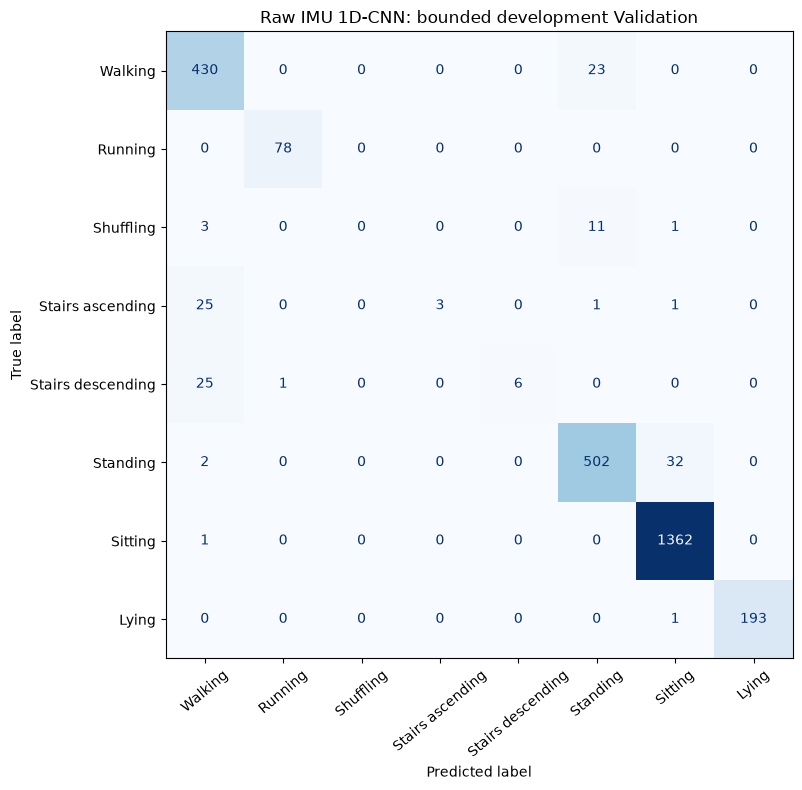

In [7]:
# ============== 07. Inspect Validation Class-Level Predictions ===============

# -------- 1. Import classification metrics for saved Validation only. --------
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix

# --------- 2. Calculate per-class precision, recall, F1 and support. ---------
report = classification_report(
    y_validation, validation_pred,
    labels=TASK_CLASSES,
    target_names=[ACTIVITY_NAMES[c] for c in TASK_CLASSES],
    output_dict=True, zero_division=0,
)

# ---------- 3. Display the original eight-class Validation report. -----------
display(pd.DataFrame(report).T.round(3))

# ------------ 4. Build a fixed-order Validation confusion matrix. ------------
confusion = confusion_matrix(y_validation, validation_pred, labels=TASK_CLASSES)

# ----------- 5. Plot real class confusions on Validation subjects. -----------
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(
    confusion_matrix=confusion,
    display_labels=[ACTIVITY_NAMES[c] for c in TASK_CLASSES],
).plot(ax=ax, cmap="Blues", xticks_rotation=40, colorbar=False)

ax.set_title("Raw IMU 1D-CNN: bounded development Validation")
fig.tight_layout()
plt.show()

**08. Scientific Quality Gate and Research Limitations**

Check the raw-signal tensor, participant separation, predictions and five-epoch training history. The saved final-epoch Validation Macro F1 is 0.6659. This is Development evidence only and is not directly comparable to the full-cohort, five-fold classical ML evaluation.

In [8]:
# ================ 08. Scientific Quality Gate and Limitations ================

# ------------ 1. Check correspondence of raw signals and labels. -------------
assert len(X_train) == len(y_train) and len(X_validation) == len(y_validation)

# ---------- 2. Require six axes and exactly 100 samples per window. ----------
assert X_train.shape[1:] == X_validation.shape[1:] == (6, 100)

# ----------- 3. Check subject-disjoint Train and Validation again. -----------
assert not (set(group_names["train"]) & set(group_names["validation"]))

# ------------- 4. Ensure predictions belong to the defined task. -------------
assert set(np.unique(validation_pred)).issubset(TASK_CLASSES)

# ------------- 5. Verify legitimate Validation Macro F1 scores. --------------
assert history["validation_macro_f1"].between(0, 1).all()

# ---------- 6. Check all five recorded training epochs are present. ----------
assert len(history) == EPOCHS

# --------- 7. Report the successfully executed raw-signal pipeline. ----------
print("Raw-signal PyTorch pipeline: PASSED")

# ----------- 8. Confirm the six held-out Validation participants. ------------
print("Validated development subjects:", len(group_names["validation"]))

# ---------- 9. Keep the remaining three Development people unused. -----------
print("Unused development subjects:", len(group_names["test"]))

# ------------- 10. Confirm the original Test was not evaluated. --------------
print("Original reserved Test loaded/scored: NO")

# --------- 11. Prevent unsupported cross-protocol benchmark claims. ----------
print("Matched full-cohort CNN vs Random Forest benchmark: NOT PERFORMED")

Raw-signal PyTorch pipeline: PASSED
Validated development subjects: 6
Unused development subjects: 3
Original reserved Test loaded/scored: NO
Matched full-cohort CNN vs Random Forest benchmark: NOT PERFORMED
